# 실습 03 · 라벨 면적·그룹 검사

> **Day15 | 객체탐지·YOLO·추적 · 02_응용**
> 원본 스크립트: `03_audit.py` · 교안 PPT 39쪽 · 직접 구현: A03
> 코드: 완성 정답 기준(주석본 `02_응용_주석/03_audit.py`와 같은 로직) · 결과: 이 노트북을 실제 실행한 출력

## 학습 목표

- 라벨에서 정규화 면적과 픽셀 가로세로비를 계산한다.
- 분할별·클래스별 객체 수와 negative 이미지 수를 확인한다.
- 그룹이 분할 경계를 넘는지, 같은 파일이 중복되는지 검사한다.

## 핵심 개념

| 개념 | 설명 |
|---|---|
| area = w·h | 이미지 대비 박스 면적 비율 |
| aspect = (w·W)/(h·H) | 픽셀 기준 가로세로비 |
| group_id | 같은 원본 묶음. 다른 split에 나뉘면 누수 |
| 빈 TXT | 정상 negative |

## 0. 준비

- 이 노트북은 `02_응용` 폴더(같은 폴더에 `data/`가 있는 위치)에서 연다.
- 입력은 `data/`의 원본을 읽기만 하고, 노트북이 만드는 결과 파일은 `outputs_notebook/`에 저장한다.
- CPU에서 실행한다. GPU·CUDA 코드는 없다.

In [1]:
# ============================================================
# 0. 라이브러리·경로 설정
# ============================================================
from pathlib import Path
import logging
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# BASE : 노트북 폴더(02_응용) / DATA : 원본 입력 / OUT : 노트북 결과 폴더
BASE = Path.cwd()
DATA = BASE / "data"
OUT = BASE / "outputs_notebook"
OUT.mkdir(exist_ok=True)
# ultralytics 로그는 WARNING 이상만 출력
logging.getLogger("ultralytics").setLevel(logging.WARNING)

def show(images, titles, size=3.2):
    """BGR 배열 여러 장을 한 줄로 표시한다.

    - images: BGR 배열 목록
    - titles: 각 그림 제목 목록 (영문)
    """
    fig, axes = plt.subplots(1, len(images), figsize=(size * len(images), size * 0.9))
    axes = np.atleast_1d(axes)
    for ax, img, title in zip(axes, images, titles):
        ax.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB)); ax.set_title(title, fontsize=9); ax.axis("off")
    plt.tight_layout(); plt.show()

## 1. 라벨 줄마다 기록 (TODO A03)

In [2]:
# ============================================================
# 1. 라벨 줄마다 면적·가로세로비 기록 (TODO A03)
# ============================================================
manifest = pd.read_csv(DATA/"manifest.csv")
rows = []
for image in manifest.itertuples():
    for line in (DATA/image.label).read_text(encoding="utf-8").splitlines():
        cls, cx, cy, w, h = map(float, line.split())
        # A03 : area=w*h, aspect=(w*W)/(h*H)
        rows.append(dict(image_id=image.image_id, split=image.split, group_id=image.group_id, class_id=int(cls),
                         area=w*h, aspect=(w*image.width)/(h*image.height)))
r = pd.DataFrame(rows); r.to_csv(OUT/"label_audit.csv", index=False)
print(r.groupby(["split", "class_id"]).size().unstack(fill_value=0).to_string())

class_id   0   1   2
split               
test      10  10  10
train     30  30  30
val       10  10  10


## 2. 분할별 이미지·negative 수

In [3]:
# ============================================================
# 2. 분할별 이미지·negative 수
# ============================================================
dist = manifest.groupby("split").agg(images=("image_id", "size"), negative=("objects", lambda s: int((s == 0).sum())), objects=("objects", "sum"), groups=("group_id", "nunique"))
dist["ratio"] = (dist.images / dist.images.sum()).round(3)
dist

,images,negative,objects,groups,ratio
split,,,,,
test,12,2,30,6,0.2
train,36,6,90,18,0.6
val,12,2,30,6,0.2


## 3. 면적·가로세로비 분포

area                                                         aspect  \
         count    mean     std     min     25%     50%     75%     max  count   
class_id                                                                        
0         50.0  0.0457  0.0132  0.0281  0.0330  0.0439  0.0582  0.0705   50.0   
1         50.0  0.0487  0.0127  0.0305  0.0363  0.0500  0.0590  0.0705   50.0   
2         50.0  0.0468  0.0139  0.0281  0.0337  0.0439  0.0598  0.0668   50.0   

                                             
         mean  std  min  25%  50%  75%  max  
class_id                                     
0         1.0  0.0  1.0  1.0  1.0  1.0  1.0  
1         1.0  0.0  1.0  1.0  1.0  1.0  1.0  
2         1.0  0.0  1.0  1.0  1.0  1.0  1.0

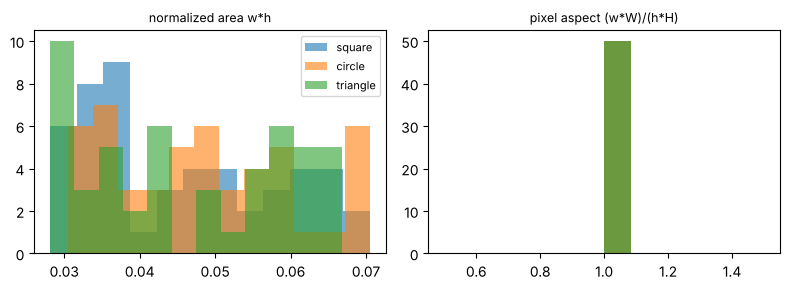

In [4]:
# ============================================================
# 3. 면적·가로세로비 분포
# ============================================================
names = {0: "square", 1: "circle", 2: "triangle"}
summary = r.groupby("class_id")[["area", "aspect"]].describe().round(4)
display(summary)
fig, axes = plt.subplots(1, 2, figsize=(8, 3))
for c in range(3):
    axes[0].hist(r[r.class_id == c].area, bins=12, alpha=0.6, label=names[c])
    axes[1].hist(r[r.class_id == c].aspect, bins=12, alpha=0.6, label=names[c])
axes[0].set_title("normalized area w*h", fontsize=9); axes[1].set_title("pixel aspect (w*W)/(h*H)", fontsize=9)
axes[0].legend(fontsize=8); plt.tight_layout(); fig.savefig(OUT/"p03_area_aspect.png", dpi=120); plt.show()

## 4. 누수·중복 검사

In [5]:
# ============================================================
# 4. 누수·중복 검사
# ============================================================
print("split 간 그룹 중복:", int((manifest.groupby("group_id").split.nunique() > 1).sum()))
print("정확히 같은 파일:", int(manifest.sha256.duplicated().sum()))
# 라벨 파일 존재 확인: 빈 파일(negative)과 누락을 구분
missing = [m.label for m in manifest.itertuples() if not (DATA/m.label).exists()]
empty = [m.label for m in manifest.itertuples() if (DATA/m.label).exists() and (DATA/m.label).read_text(encoding="utf-8").strip() == ""]
print("누락 라벨:", len(missing), "| 빈 라벨(정상 negative):", len(empty))
print("주의: 정규화 w/h로 바로 나누면 aspect가 W/H=1.25배 틀어짐 ->", round(float((r.aspect * 128 / 160).mean()), 4), "(잘못된 평균) vs", round(float(r.aspect.mean()), 4))

split 간 그룹 중복: 0
정확히 같은 파일: 0
누락 라벨: 0 | 빈 라벨(정상 negative): 10
주의: 정규화 w/h로 바로 나누면 aspect가 W/H=1.25배 틀어짐 -> 0.8 (잘못된 평균) vs 1.0


## 정리 (README 설명 질문)

- **무엇을 고정했고 무엇을 바꾸었는가?** manifest·라벨 원본을 그대로 읽고 계산만 추가했다. 분할(train 36·val 12·test 12)과 그룹은 바꾸지 않았다.
- **결과만으로 단정할 수 없는 부분은?** 그룹 중복 0·SHA 중복 0은 "완전히 같은 파일"과 "manifest의 그룹 표시"만 검사한 결과다. 비슷한 장면·같은 생성 seed처럼 내용이 닮은 이미지는 이 검사로 찾지 못한다.